# A5b — Tree-based classification: Random Forest vs Tree Boosting

Sprint issue: **"Challenge the current champion regression/classification with a tree-based approach"**

This notebook:
- Builds WeakestLink classification dataset (same structure as earlier notebooks)
- Trains & tunes:
  - RandomForestClassifier
  - HistGradientBoostingClassifier (tree boosting)
- Logs runs to MLflow (same env/path strategy)
- Compares both models against each other and against the current champion model

### Imports

In [2]:
import os
import json
import glob
import warnings
from pathlib import Path
from typing import Dict, Any, Tuple

import numpy as np
import pandas as pd

import mlflow
import mlflow.sklearn

from dotenv import load_dotenv
from os import getenv

import joblib

from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score, log_loss
)


from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier,
    BaggingClassifier,
)
from sklearn.tree import DecisionTreeClassifier
# Optional: silence noisy warnings
warnings.filterwarnings("ignore", category=FutureWarning, module="mlflow")

# Optional TLS warning suppression (if you have self-signed certs on MLflow server)
try:
    import urllib3
    urllib3.disable_warnings(urllib3.exceptions.InsecureRequestWarning)
except Exception:
    pass

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

### Paths + Load Data

In [3]:
from pathlib import Path

SCORES_PATH   = Path("../../../data/processed/20190108_scores_and_weak_links.csv")
FEATURES_PATH = Path("../../../data/processed/AimoScore_WeakLink_big_scores.csv")

scores = pd.read_csv(SCORES_PATH)
big = pd.read_csv(FEATURES_PATH)

print("scores:", scores.shape)
print("big:", big.shape)

scores: (2096, 17)
big: (2094, 43)


### MLflow connection

In [4]:
# Adjust this path to where your env file truly is.
# If your file is named ".env" in repo root, use: load_dotenv("../../../../.env")
load_dotenv("../../../../../../env")

tracking_uri = getenv("MLFLOW_TRACKING_URI")
print("MLFLOW_TRACKING_URI =", tracking_uri)

if tracking_uri:
    mlflow.set_tracking_uri(tracking_uri)
else:
    raise RuntimeError("MLFLOW_TRACKING_URI not set. Fix your env path or env variable.")

EXPERIMENT_NAME = "A5b_tree_classification"
mlflow.set_experiment(EXPERIMENT_NAME)

print("MLflow tracking URI:", mlflow.get_tracking_uri())
print("MLflow experiment:", EXPERIMENT_NAME)

MLFLOW_TRACKING_URI = https://172.27.62.170:5001/
MLflow tracking URI: https://172.27.62.170:5001/
MLflow experiment: A5b_tree_classification


### Helper functions

In [5]:
def classification_metrics(y_true, y_pred, proba=None, classes=None):
    out = {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(y_true, y_pred, average="macro")),
        "weighted_f1": float(f1_score(y_true, y_pred, average="weighted")),
    }
    if proba is not None:
        # For log_loss, labels MUST match the columns in proba
        labels_for_ll = classes if classes is not None else np.array(sorted(np.unique(y_true)), dtype=object)
        out["log_loss"] = float(log_loss(y_true, proba, labels=labels_for_ll))
    return out

def load_meta(dir_path: str):
    meta_candidates = glob.glob(os.path.join(dir_path, "*meta*.json"))
    if not meta_candidates:
        return None
    with open(meta_candidates[0], "r") as f:
        return json.load(f)

def align_X(X, meta):
    if meta is None:
        return X
    feat_cols = meta.get("feature_cols", None)
    if feat_cols is None:
        return X
    if isinstance(X, pd.DataFrame):
        missing = [c for c in feat_cols if c not in X.columns]
        if missing:
            raise ValueError(f"X missing expected columns (first 10): {missing[:10]}")
        return X[feat_cols]
    return X

# Collect best estimators + metrics in one place for later comparison
best_models = {}
metrics_by_model = {}

def log_and_store(model_name: str, estimator, metrics: dict):
    best_models[model_name] = estimator
    metrics_by_model[model_name] = metrics

## Build WeakestLink classification dataset

In [6]:
NON_INDICATORS = {"ID", "Date", "SCORE"}
indicator_cols = [c for c in scores.columns if c not in NON_INDICATORS]

DROP_CLASSES = True
DROP_WEAK_LINKS = {
    "LeftHeelRises",
    "RightHeelRises",
    "LeftKneeMovesInward",
    "RightAsymmetricalWeightShift",
}
DROP_TIES = True

if DROP_CLASSES:
    indicator_cols = [c for c in indicator_cols if c not in DROP_WEAK_LINKS]

scores[indicator_cols] = scores[indicator_cols].apply(pd.to_numeric, errors="coerce")

row_max = scores[indicator_cols].max(axis=1)
ties = (scores[indicator_cols].eq(row_max, axis=0).sum(axis=1) > 1)

scores["WeakestLink"] = scores[indicator_cols].idxmax(axis=1)
scores["HasTie"] = ties

scores_labeled = scores.loc[~scores["HasTie"]].copy() if DROP_TIES else scores.copy()
scores_labeled = scores_labeled.dropna(subset=["WeakestLink"])

labels = scores_labeled[["ID", "WeakestLink"]]
data = big.merge(labels, on="ID", how="inner")

angle_cols = [c for c in data.columns if c.startswith("No_") and c.endswith("_Angle_Deviation")]
nasm_cols  = [c for c in data.columns if c.startswith("No_") and c.endswith("_NASM_Deviation")]
feature_cols = sorted(angle_cols) + sorted(nasm_cols)

X = data[feature_cols].apply(pd.to_numeric, errors="coerce")
y = data["WeakestLink"].astype(str)

mask = X.notna().all(axis=1)
X = X.loc[mask].reset_index(drop=True)
y = y.loc[mask].reset_index(drop=True)

ALL_CLASSES = np.array(sorted(y.unique()), dtype=object)

print("X:", X.shape, "y:", y.shape, "n_classes:", len(ALL_CLASSES))
print("Top class counts:\n", y.value_counts().head(10))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_SEED, stratify=y
)

print("Train:", X_train.shape, "Test:", X_test.shape)

X: (1724, 38) y: (1724,) n_classes: 10
Top class counts:
 WeakestLink
RightArmFallForward            454
LeftArmFallForward             328
RightKneeMovesOutward          278
RightShoulderElevation         252
ExcessiveForwardLean            99
ForwardHead                     96
LeftAsymmetricalWeightShift     71
LeftShoulderElevation           51
LeftKneeMovesOutward            49
RightKneeMovesInward            46
Name: count, dtype: int64
Train: (1379, 38) Test: (345, 38)


## Model 1 — Random Forest (tuned) + MLflow logging

In [7]:
rf = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("rf", RandomForestClassifier(random_state=RANDOM_SEED, n_jobs=-1))
])

param_distributions_rf = {
    "rf__n_estimators": [300, 600, 1000],
    "rf__max_depth": [None, 8, 12, 18, 26],
    "rf__min_samples_split": [2, 5, 10],
    "rf__min_samples_leaf": [1, 2, 4],
    "rf__max_features": ["sqrt", "log2", 0.5, 1.0],
    "rf__class_weight": [None, "balanced"],
    "rf__bootstrap": [True],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

search_rf = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_distributions_rf,
    n_iter=25,
    scoring="balanced_accuracy",
    cv=cv,
    random_state=RANDOM_SEED,
    n_jobs=-1,
    verbose=0,
)

with mlflow.start_run(run_name="CLF_random_forest") as run:
    mlflow.log_param("task", "classification")
    mlflow.log_param("model_family", "random_forest")
    mlflow.log_param("random_seed", RANDOM_SEED)
    mlflow.log_param("cv_folds", 5)
    mlflow.log_param("search_n_iter", 25)

    search_rf.fit(X_train, y_train)
    best_rf = search_rf.best_estimator_

    proba_rf = best_rf.predict_proba(X_test)
    pred_rf = best_rf.predict(X_test)

    metrics_rf = classification_metrics(
        y_test, pred_rf, proba=proba_rf, classes=best_rf.named_steps["rf"].classes_
    )

    mlflow.log_params(search_rf.best_params_)
    mlflow.log_metrics(metrics_rf)
    mlflow.sklearn.log_model(best_rf, name="model")

log_and_store("random_forest", best_rf, metrics_rf)

print("Best RF params:", search_rf.best_params_)
print("RF metrics:", metrics_rf)


🏃 View run CLF_random_forest at: https://172.27.62.170:5001/#/experiments/8/runs/686cdca246244796bb9e7a6755b4b80d
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/8
Best RF params: {'rf__n_estimators': 600, 'rf__min_samples_split': 10, 'rf__min_samples_leaf': 4, 'rf__max_features': 0.5, 'rf__max_depth': 26, 'rf__class_weight': 'balanced', 'rf__bootstrap': True}
RF metrics: {'accuracy': 0.6318840579710145, 'balanced_accuracy': 0.5791715010136063, 'macro_f1': 0.5433144501660603, 'weighted_f1': 0.6396864478777651, 'log_loss': 1.1201218382480245}


## Model 2 ExtraTrees

In [8]:
# Model 2 — ExtraTrees (Extremely Randomized Trees) + MLflow logging

et = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("et", ExtraTreesClassifier(random_state=RANDOM_SEED, n_jobs=-1))
])

param_distributions_et = {
    "et__n_estimators": [300, 600, 1000],
    "et__max_depth": [None, 8, 12, 18, 26],
    "et__min_samples_split": [2, 5, 10],
    "et__min_samples_leaf": [1, 2, 4],
    "et__max_features": ["sqrt", "log2", 0.5, 1.0],
    "et__class_weight": [None, "balanced"],
    "et__bootstrap": [False, True],
}

search_et = RandomizedSearchCV(
    estimator=et,
    param_distributions=param_distributions_et,
    n_iter=25,
    scoring="balanced_accuracy",
    cv=cv,
    random_state=RANDOM_SEED,
    n_jobs=-1,
    verbose=0,
)

with mlflow.start_run(run_name="CLF_extra_trees") as run:
    mlflow.log_param("task", "classification")
    mlflow.log_param("model_family", "forest")
    mlflow.log_param("model_name", "extra_trees")
    mlflow.log_param("random_seed", RANDOM_SEED)
    mlflow.log_param("cv_folds", 5)
    mlflow.log_param("search_n_iter", 25)

    search_et.fit(X_train, y_train)
    best_et = search_et.best_estimator_

    proba_et = best_et.predict_proba(X_test)
    pred_et = best_et.predict(X_test)

    metrics_et = classification_metrics(
        y_test, pred_et, proba=proba_et, classes=best_et.named_steps["et"].classes_
    )

    mlflow.log_params(search_et.best_params_)
    mlflow.log_metrics(metrics_et)
    mlflow.sklearn.log_model(best_et, name="model")

log_and_store("extra_trees", best_et, metrics_et)

print("Best ET params:", search_et.best_params_)
print("ET metrics:", metrics_et)



🏃 View run CLF_extra_trees at: https://172.27.62.170:5001/#/experiments/8/runs/a4757ff71a1148a4889a348b3fc5833d
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/8
Best ET params: {'et__n_estimators': 1000, 'et__min_samples_split': 10, 'et__min_samples_leaf': 4, 'et__max_features': 'sqrt', 'et__max_depth': 8, 'et__class_weight': 'balanced', 'et__bootstrap': False}
ET metrics: {'accuracy': 0.5623188405797102, 'balanced_accuracy': 0.5954517529254371, 'macro_f1': 0.4971205902386746, 'weighted_f1': 0.5699904374802919, 'log_loss': 1.3886936467153899}


## Model 3 Bagging of decision trees

In [9]:
# Model 3 — Bagging of Decision Trees (RF-like) + MLflow logging

bag = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("bag", BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=RANDOM_SEED),
        random_state=RANDOM_SEED,
        n_jobs=-1
    ))
])

param_distributions_bag = {
    "bag__n_estimators": [50, 100, 200],
    "bag__max_samples": [0.5, 0.7, 1.0],
    "bag__max_features": [0.5, 0.7, 1.0],
    "bag__estimator__max_depth": [None, 5, 10, 20],
    "bag__estimator__min_samples_split": [2, 5, 10],
    "bag__estimator__min_samples_leaf": [1, 2, 4],
}

search_bag = RandomizedSearchCV(
    estimator=bag,
    param_distributions=param_distributions_bag,
    n_iter=25,
    scoring="balanced_accuracy",
    cv=cv,
    random_state=RANDOM_SEED,
    n_jobs=-1,
    verbose=0,
)

with mlflow.start_run(run_name="CLF_bagged_trees") as run:
    mlflow.log_param("task", "classification")
    mlflow.log_param("model_family", "forest")
    mlflow.log_param("model_name", "bagged_trees")
    mlflow.log_param("random_seed", RANDOM_SEED)
    mlflow.log_param("cv_folds", 5)
    mlflow.log_param("search_n_iter", 25)

    search_bag.fit(X_train, y_train)
    best_bag = search_bag.best_estimator_

    proba_bag = best_bag.predict_proba(X_test)
    pred_bag = best_bag.predict(X_test)

    metrics_bag = classification_metrics(
        y_test, pred_bag, proba=proba_bag, classes=best_bag.named_steps["bag"].classes_
    )

    mlflow.log_params(search_bag.best_params_)
    mlflow.log_metrics(metrics_bag)
    mlflow.sklearn.log_model(best_bag, name="model")

log_and_store("bagged_trees", best_bag, metrics_bag)

print("Best BAG params:", search_bag.best_params_)
print("BAG metrics:", metrics_bag)



🏃 View run CLF_bagged_trees at: https://172.27.62.170:5001/#/experiments/8/runs/ee34f013d22f40058fad0cd9a262519e
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/8
Best BAG params: {'bag__n_estimators': 50, 'bag__max_samples': 0.5, 'bag__max_features': 1.0, 'bag__estimator__min_samples_split': 5, 'bag__estimator__min_samples_leaf': 2, 'bag__estimator__max_depth': 20}
BAG metrics: {'accuracy': 0.5971014492753624, 'balanced_accuracy': 0.4279858913016808, 'macro_f1': 0.41581570955212255, 'weighted_f1': 0.5712922394357491, 'log_loss': 1.290651028922644}


## Model 4 — Tree Boosting (HistGradientBoostingClassifier) + MLflow logging

Note: This uses sklearn's histogram-based gradient boosting, which is usually strong and fast.

### Boosting training + MLflow

In [10]:
# HistGradientBoostingClassifier cannot handle NaNs in older versions consistently,
# so we keep the same imputer pipeline structure.
hgb = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("hgb", HistGradientBoostingClassifier(
        random_state=RANDOM_SEED
    ))
])

param_distributions_hgb = {
    "hgb__learning_rate": [0.03, 0.05, 0.1, 0.2],
    "hgb__max_depth": [None, 3, 5, 8, 12],
    "hgb__max_leaf_nodes": [15, 31, 63, 127],
    "hgb__min_samples_leaf": [10, 20, 30, 50],
    "hgb__l2_regularization": [0.0, 0.1, 1.0, 5.0],
    "hgb__max_iter": [200, 400, 800],
}

search_hgb = RandomizedSearchCV(
    estimator=hgb,
    param_distributions=param_distributions_hgb,
    n_iter=25,
    scoring="balanced_accuracy",
    cv=cv,
    random_state=RANDOM_SEED,
    n_jobs=-1,
    verbose=0,
)

with mlflow.start_run(run_name="CLF_tree_boosting") as run:
    mlflow.log_param("task", "classification")
    mlflow.log_param("model_family", "hist_gradient_boosting")
    mlflow.log_param("random_seed", RANDOM_SEED)
    mlflow.log_param("cv_folds", 5)
    mlflow.log_param("search_n_iter", 25)

    search_hgb.fit(X_train, y_train)
    best_hgb = search_hgb.best_estimator_

    # predict_proba is available if loss is log_loss (default) in newer sklearn; keep safe:
    if hasattr(best_hgb, "predict_proba"):
        proba_hgb = best_hgb.predict_proba(X_test)
    else:
        proba_hgb = None

    pred_hgb = best_hgb.predict(X_test)

    classes_hgb = None
    if hasattr(best_hgb.named_steps["hgb"], "classes_"):
        classes_hgb = best_hgb.named_steps["hgb"].classes_

    metrics_hgb = classification_metrics(
        y_test, pred_hgb, proba=proba_hgb, classes=classes_hgb
    )

    mlflow.log_params(search_hgb.best_params_)
    mlflow.log_metrics(metrics_hgb)
    mlflow.sklearn.log_model(best_hgb, name="model")

log_and_store("hist_gradient_boosting", best_hgb, metrics_hgb)

print("Best HGB params:", search_hgb.best_params_)
print("HGB metrics:", metrics_hgb)



🏃 View run CLF_tree_boosting at: https://172.27.62.170:5001/#/experiments/8/runs/47d5e620e7ed4ae2b369bf95b127bd29
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/8
Best HGB params: {'hgb__min_samples_leaf': 20, 'hgb__max_leaf_nodes': 31, 'hgb__max_iter': 200, 'hgb__max_depth': None, 'hgb__learning_rate': 0.2, 'hgb__l2_regularization': 0.1}
HGB metrics: {'accuracy': 0.663768115942029, 'balanced_accuracy': 0.5481671398776661, 'macro_f1': 0.5522275287286076, 'weighted_f1': 0.654381440617033, 'log_loss': 1.3875564256705957}


## Model 5 GradientBoostingClassifier

In [11]:
# Model 5 — GradientBoostingClassifier + MLflow logging

gb = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("gb", GradientBoostingClassifier(random_state=RANDOM_SEED))
])

param_distributions_gb = {
    "gb__n_estimators": [100, 200, 400],
    "gb__learning_rate": [0.03, 0.05, 0.1, 0.2],
    "gb__max_depth": [2, 3, 5],
    "gb__subsample": [0.6, 0.8, 1.0],
    "gb__min_samples_split": [2, 5, 10],
    "gb__min_samples_leaf": [1, 2, 4],
}

search_gb = RandomizedSearchCV(
    estimator=gb,
    param_distributions=param_distributions_gb,
    n_iter=25,
    scoring="balanced_accuracy",
    cv=cv,
    random_state=RANDOM_SEED,
    n_jobs=-1,
    verbose=0,
)

with mlflow.start_run(run_name="CLF_gradient_boosting") as run:
    mlflow.log_param("task", "classification")
    mlflow.log_param("model_family", "boosting")
    mlflow.log_param("model_name", "gradient_boosting")
    mlflow.log_param("random_seed", RANDOM_SEED)
    mlflow.log_param("cv_folds", 5)
    mlflow.log_param("search_n_iter", 25)

    search_gb.fit(X_train, y_train)
    best_gb = search_gb.best_estimator_

    proba_gb = best_gb.predict_proba(X_test)
    pred_gb = best_gb.predict(X_test)

    metrics_gb = classification_metrics(
        y_test, pred_gb, proba=proba_gb, classes=best_gb.named_steps["gb"].classes_
    )

    mlflow.log_params(search_gb.best_params_)
    mlflow.log_metrics(metrics_gb)
    mlflow.sklearn.log_model(best_gb, name="model")
    
    
log_and_store("gradient_boosting", best_gb, metrics_gb)    

print("Best GB params:", search_gb.best_params_)
print("GB metrics:", metrics_gb)

🏃 View run CLF_gradient_boosting at: https://172.27.62.170:5001/#/experiments/8/runs/6e379bca6a7643dfbb70a3fa33ded0ae
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/8
Best GB params: {'gb__subsample': 0.8, 'gb__n_estimators': 200, 'gb__min_samples_split': 10, 'gb__min_samples_leaf': 2, 'gb__max_depth': 2, 'gb__learning_rate': 0.1}
GB metrics: {'accuracy': 0.6289855072463768, 'balanced_accuracy': 0.5283931682352735, 'macro_f1': 0.5273445018657784, 'weighted_f1': 0.6193104986120712, 'log_loss': 0.9715458587491893}


## Model 6 Adaboost

In [12]:
# Model 6 — AdaBoost (DecisionTree base) + MLflow logging

ada = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("ada", AdaBoostClassifier(
        estimator=DecisionTreeClassifier(random_state=RANDOM_SEED),
        random_state=RANDOM_SEED
    ))
])

param_distributions_ada = {
    "ada__n_estimators": [100, 200, 400],
    "ada__learning_rate": [0.03, 0.05, 0.1, 0.2, 0.5, 1.0],
    "ada__estimator__max_depth": [1, 2, 3],
    "ada__estimator__min_samples_leaf": [1, 2, 4],
}

search_ada = RandomizedSearchCV(
    estimator=ada,
    param_distributions=param_distributions_ada,
    n_iter=25,
    scoring="balanced_accuracy",
    cv=cv,
    random_state=RANDOM_SEED,
    n_jobs=-1,
    verbose=0,
)

with mlflow.start_run(run_name="CLF_adaboost") as run:
    mlflow.log_param("task", "classification")
    mlflow.log_param("model_family", "boosting")
    mlflow.log_param("model_name", "adaboost")
    mlflow.log_param("random_seed", RANDOM_SEED)
    mlflow.log_param("cv_folds", 5)
    mlflow.log_param("search_n_iter", 25)

    search_ada.fit(X_train, y_train)
    best_ada = search_ada.best_estimator_

    proba_ada = best_ada.predict_proba(X_test)
    pred_ada = best_ada.predict(X_test)

    metrics_ada = classification_metrics(
        y_test, pred_ada, proba=proba_ada, classes=best_ada.named_steps["ada"].classes_
    )

    mlflow.log_params(search_ada.best_params_)
    mlflow.log_metrics(metrics_ada)
    mlflow.sklearn.log_model(best_ada, name="model")

print("Best ADA params:", search_ada.best_params_)
print("ADA metrics:", metrics_ada)

log_and_store("adaboost", best_ada, metrics_ada)

🏃 View run CLF_adaboost at: https://172.27.62.170:5001/#/experiments/8/runs/d62b4dce9a194eccba421dc692a29173
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/8
Best ADA params: {'ada__n_estimators': 400, 'ada__learning_rate': 1.0, 'ada__estimator__min_samples_leaf': 2, 'ada__estimator__max_depth': 3}
ADA metrics: {'accuracy': 0.5710144927536231, 'balanced_accuracy': 0.44206513661776814, 'macro_f1': 0.4440937319336296, 'weighted_f1': 0.5581557134629501, 'log_loss': 2.2900621711979636}


## Compare: Random Forest vs Tree Boosting

### Side-by-side comparison

In [14]:
df_compare = (
    pd.DataFrame(
        [{"model": k, **v} for k, v in metrics_by_model.items()]
    )
    .sort_values(["weighted_f1", "balanced_accuracy", "macro_f1", "accuracy"], ascending=False)
    .reset_index(drop=True)
)

display(df_compare)

,model,accuracy,balanced_accuracy,macro_f1,weighted_f1,log_loss
0,hist_gradient_boosting,0.663768,0.548167,0.552228,0.654381,1.387556
1,random_forest,0.631884,0.579172,0.543314,0.639686,1.120122
2,gradient_boosting,0.628986,0.528393,0.527345,0.619310,0.971546
3,bagged_trees,0.597101,0.427986,0.415816,0.571292,1.290651
4,extra_trees,0.562319,0.595452,0.497121,0.569990,1.388694
5,adaboost,0.571014,0.442065,0.444094,0.558156,2.290062


## Compare both models against the current champion classification model

### Load champion model + evaluate

In [15]:
import joblib

weakest_dir = "../../../../trained_models/weakest_link_model"
weakest_meta = load_meta(weakest_dir)

champion = joblib.load(os.path.join(weakest_dir, "champion_model.joblib"))
print("Loaded champion:", type(champion))

X_test_aligned = align_X(X_test.copy(), weakest_meta)

proba_champ = champion.predict_proba(X_test_aligned)

# Always use model classes to decode predictions + for log_loss
classes_champ = getattr(champion, "classes_", None)
if classes_champ is None:
    # If pipeline: final estimator might hold classes_
    try:
        classes_champ = champion.named_steps[list(champion.named_steps.keys())[-1]].classes_
    except Exception:
        classes_champ = np.array(sorted(np.unique(y_train)), dtype=object)

pred_champ = classes_champ[np.argmax(proba_champ, axis=1)]

metrics_champ = classification_metrics(
    y_test, pred_champ, proba=proba_champ, classes=classes_champ
)
print("Champion metrics:", metrics_champ)

Loaded champion: <class 'sklearn.pipeline.Pipeline'>
Champion metrics: {'accuracy': 0.591304347826087, 'balanced_accuracy': 0.5439776217934114, 'macro_f1': 0.44620256157594723, 'weighted_f1': 0.597769338022715, 'log_loss': 1.1436939889426352}


c:\Users\kimwo\software engineering\year 4\LP3\4DT907 - Project\machine_learning_project_4dt907\.venv\Lib\site-packages\sklearn\metrics\_classification.py:2924: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


### Final comparison table + deltas vs champion

In [16]:
rows = [{"model": "champion_weakest_link_model", **metrics_champ}]
rows += [{"model": k, **v} for k, v in metrics_by_model.items()]

df_vs_champ = (
    pd.DataFrame(rows)
    .sort_values(["balanced_accuracy", "macro_f1", "accuracy"], ascending=False)
    .reset_index(drop=True)
)

display(df_vs_champ)

def deltas(a, b):
    # a - b
    out = {}
    for k in ["accuracy", "balanced_accuracy", "macro_f1", "weighted_f1"]:
        out[f"delta_{k}"] = a.get(k, np.nan) - b.get(k, np.nan)
    if "log_loss" in a and "log_loss" in b:
        out["delta_log_loss"] = a["log_loss"] - b["log_loss"]
    return out

for name, m in metrics_by_model.items():
    print(f"{name} - Champion:", deltas(m, metrics_champ))

,model,accuracy,balanced_accuracy,macro_f1,weighted_f1,log_loss
0,extra_trees,0.562319,0.595452,0.497121,0.569990,1.388694
1,random_forest,0.631884,0.579172,0.543314,0.639686,1.120122
2,hist_gradient_boosting,0.663768,0.548167,0.552228,0.654381,1.387556
3,champion_weakest_link_model,0.591304,0.543978,0.446203,0.597769,1.143694
4,gradient_boosting,0.628986,0.528393,0.527345,0.619310,0.971546
5,adaboost,0.571014,0.442065,0.444094,0.558156,2.290062
6,bagged_trees,0.597101,0.427986,0.415816,0.571292,1.290651


random_forest - Champion: {'delta_accuracy': 0.04057971014492756, 'delta_balanced_accuracy': 0.0351938792201949, 'delta_macro_f1': 0.09711188859011305, 'delta_weighted_f1': 0.04191710985505004, 'delta_log_loss': -0.023572150694610716}
extra_trees - Champion: {'delta_accuracy': -0.02898550724637683, 'delta_balanced_accuracy': 0.0514741311320257, 'delta_macro_f1': 0.05091802866272738, 'delta_weighted_f1': -0.027778900542423157, 'delta_log_loss': 0.24499965777275468}
bagged_trees - Champion: {'delta_accuracy': 0.005797101449275366, 'delta_balanced_accuracy': -0.11599173049173056, 'delta_macro_f1': -0.030386852023824684, 'delta_weighted_f1': -0.026477098586965897, 'delta_log_loss': 0.14695703998000886}
hist_gradient_boosting - Champion: {'delta_accuracy': 0.07246376811594202, 'delta_balanced_accuracy': 0.0041895180842547175, 'delta_macro_f1': 0.10602496715266035, 'delta_weighted_f1': 0.056612102594317926, 'delta_log_loss': 0.24386243672796049}
gradient_boosting - Champion: {'delta_accuracy

### MLflow summary run

In [17]:
with mlflow.start_run(run_name="A5b_summary_vs_champion") as run:
    mlflow.log_param("task", "classification_summary")

    # RF deltas (A6 - champion)
    for k, v in deltas(metrics_rf, metrics_champ).items():
        mlflow.log_metric(f"rf_{k}", float(v))

    # HGB deltas (A6 - champion)
    for k, v in deltas(metrics_hgb, metrics_champ).items():
        mlflow.log_metric(f"hgb_{k}", float(v))

print("Logged delta summary to MLflow.")

🏃 View run A5b_summary_vs_champion at: https://172.27.62.170:5001/#/experiments/8/runs/c88a723080604bacb95c7bd616c29f45
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/8
Logged delta summary to MLflow.


## Statistical comparison (Random Forest vs Tree Boosting)

We test whether performance differences are statistically significant using:
- Paired t-test on cross-validation fold scores
- Wilcoxon signed-rank test (non-parametric)
- Cohen’s d (paired effect size)
- McNemar’s test on the held-out test set (paired errors)

### KDE

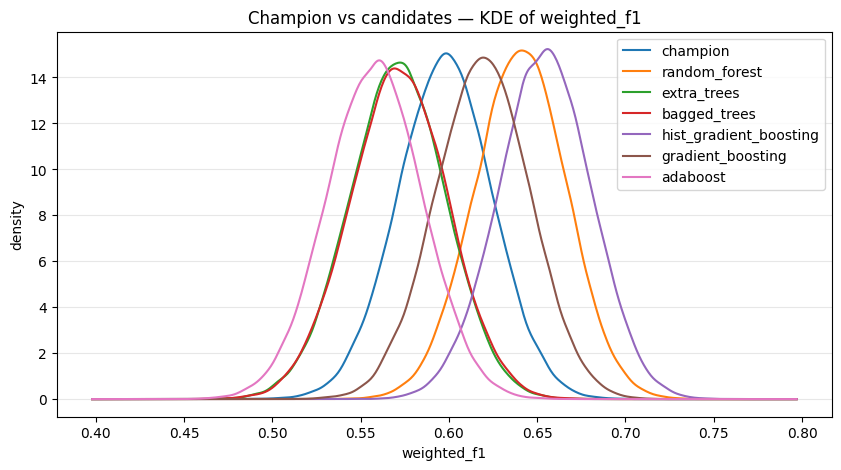

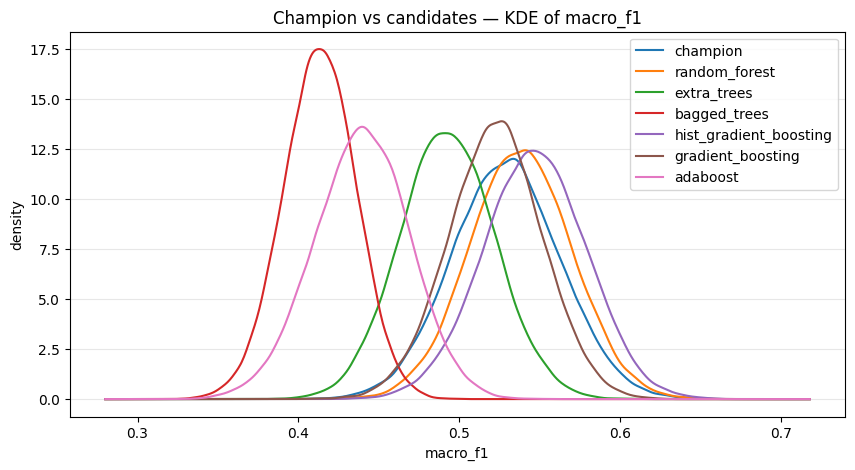

In [21]:
# =========================
# KDE plots (Champion + all models)
# Uses BOOTSTRAP distributions on the held-out test set
# (stable + gives the "normal distribution-like" curves)
# =========================

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from sklearn.metrics import f1_score, accuracy_score, balanced_accuracy_score

import warnings
warnings.filterwarnings("ignore", message="y_pred contains classes not in y_true")

def bootstrap_metric(y_true, y_pred, metric_fn, n_boot=3000, seed=42):
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    n = len(y_true)

    stats = np.empty(n_boot, dtype=float)
    for i in range(n_boot):
        idx = rng.integers(0, n, size=n)  # sample with replacement
        stats[i] = metric_fn(y_true[idx], y_pred[idx])
    return stats

def kde_plot_distributions(samples_by_model, metric_name, title=None, bw_method="silverman", jitter=0.0):
    """
    bw_method: 'scott', 'silverman', or a float (e.g., 0.2–1.0) for more smoothing
    jitter: small noise added to samples (e.g., 0.0005) to reduce discretization bumps
    """
    cleaned = {}
    for name, arr in samples_by_model.items():
        arr = np.asarray(arr, dtype=float)
        arr = arr[np.isfinite(arr)]
        if len(arr) < 50:
            continue

        # Optional jitter for discrete metrics (makes KDE smoother)
        if jitter > 0:
            arr = arr + np.random.normal(0, jitter, size=len(arr))

        cleaned[name] = arr

    if len(cleaned) < 2:
        print(f"Not enough valid distributions to plot for {metric_name}.")
        return

    all_vals = np.concatenate(list(cleaned.values()))
    xmin, xmax = float(all_vals.min()), float(all_vals.max())
    pad = (xmax - xmin) * 0.10 if xmax > xmin else 0.01
    x = np.linspace(xmin - pad, xmax + pad, 600)

    plt.figure(figsize=(10, 5))
    for name, arr in cleaned.items():
        kde = gaussian_kde(arr, bw_method=bw_method)
        y = kde(x)
        plt.plot(x, y, label=name)

    plt.title(title or f"KDE comparison — {metric_name}")
    plt.xlabel(metric_name)
    plt.ylabel("density")
    plt.grid(True, axis="y", alpha=0.3)
    plt.legend()
    plt.show()


# --- Build predictions for champion + all models on the SAME test set ---
# champion uses aligned features
preds = {}

# Champion
preds["champion"] = pred_champ  # you already computed pred_champ in your champion cell

# All candidate models
for name, model in best_models.items():
    preds[name] = model.predict(X_test)

# --- Define metrics ---
metrics = {
    "weighted_f1": lambda yt, yp: f1_score(yt, yp, average="weighted", labels=ALL_CLASSES, zero_division=0),
    "macro_f1": lambda yt, yp: f1_score(yt, yp, average="macro", labels=ALL_CLASSES, zero_division=0),
    #"balanced_accuracy": lambda yt, yp: balanced_accuracy_score(yt, yp),
    #"accuracy": lambda yt, yp: accuracy_score(yt, yp),
}

# --- Bootstrap distributions and plot KDEs ---
N_BOOT = 50000
base_seed = RANDOM_SEED

for metric_name, metric_fn in metrics.items():
    samples = {}
    for i, (name, y_pred) in enumerate(preds.items()):
        samples[name] = bootstrap_metric(
            y_test, y_pred, metric_fn,
            n_boot=N_BOOT,
            seed=base_seed + i * 13  # deterministic but different per model
        )

    kde_plot_distributions(samples, metric_name, title=f"Champion vs candidates — KDE of {metric_name}")

### Quantative analysis of the KDE plot

In [ ]:
import numpy as np

def summarize(arr):
    return {
        "mean": float(np.mean(arr)),
        "median": float(np.median(arr)),
        "p2.5": float(np.percentile(arr, 2.5)),
        "p97.5": float(np.percentile(arr, 97.5)),
        "std": float(np.std(arr, ddof=1)),
    }

# assuming you already computed bootstrap arrays per model in your KDE cell
# e.g. samples["champion"], samples["hist_gradient_boosting"], etc.

metric = "macro_f1"

# rebuild samples quickly from your last KDE loop if needed:
# samples = {...}  # model -> bootstrap array

summary_table = []
for name, arr in samples.items():
    s = summarize(arr)
    summary_table.append({"model": name, **s})

df_summary = pd.DataFrame(summary_table).sort_values("median", ascending=False)
display(df_summary)

# probability that the best model beats the champion
best_model = df_summary.iloc[0]["model"]
diff = samples["hist_gradient_boosting"] - samples["champion"]
p_best_beats_champ = float(np.mean(diff > 0))
print(f"P({best_model} > champion) on {metric} =", p_best_beats_champ)

,model,mean,median,p2.5,p97.5,std
4,hist_gradient_boosting,0.546658,0.546781,0.483392,0.608560,0.031956
1,random_forest,0.538070,0.538001,0.475918,0.600447,0.031687
0,champion,0.528990,0.529001,0.463879,0.595207,0.033501
5,gradient_boosting,0.522303,0.522613,0.464341,0.579033,0.029076
2,extra_trees,0.492685,0.492494,0.435680,0.551092,0.029371
6,adaboost,0.439063,0.439628,0.379591,0.495571,0.029432
3,bagged_trees,0.412967,0.413221,0.367926,0.456586,0.022617


P(hist_gradient_boosting > champion) on macro_f1 = 0.64894


### Improved KDE plot

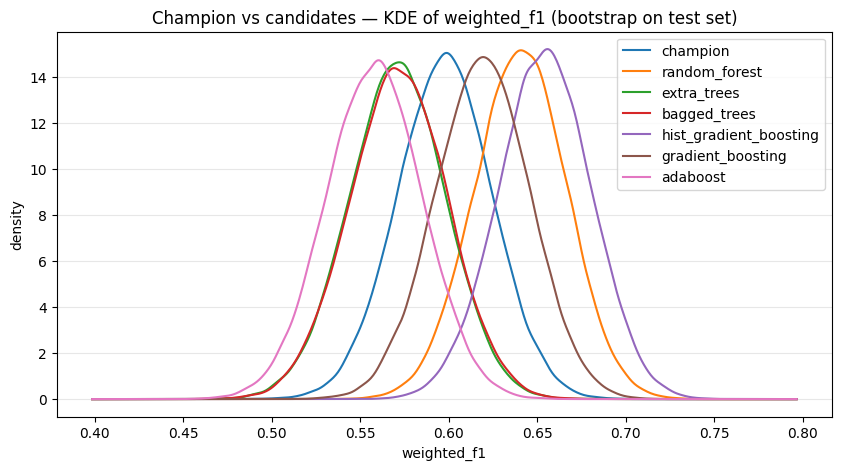


=== Summary (bootstrap) for weighted_f1 ===


,model,mean,median,std,p2.5,p97.5
0,hist_gradient_boosting,0.654191,0.654377,0.026130,0.602270,0.704755
1,random_forest,0.640456,0.640679,0.025896,0.589459,0.690451
2,gradient_boosting,0.619106,0.619261,0.026596,0.566530,0.670696
3,champion,0.597718,0.597871,0.026708,0.545017,0.650076
4,bagged_trees,0.571638,0.571681,0.027562,0.517315,0.625326
5,extra_trees,0.570978,0.571109,0.027165,0.517330,0.623661
6,adaboost,0.557941,0.558154,0.027121,0.504865,0.610750


Best by median: hist_gradient_boosting
Vs champion (weighted_f1): {'P(a > b)': 0.9335, 'median_diff(a-b)': 0.05638086534692788, 'diff_p2.5': -0.016756569585022533, 'diff_p97.5': 0.12958807794014204}


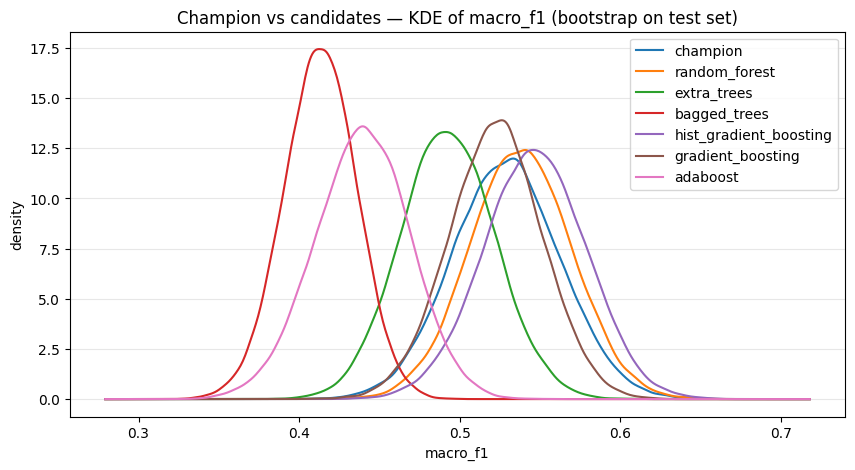


=== Summary (bootstrap) for macro_f1 ===


,model,mean,median,std,p2.5,p97.5
0,hist_gradient_boosting,0.546658,0.546781,0.031956,0.483392,0.608560
1,random_forest,0.538070,0.538001,0.031687,0.475918,0.600447
2,champion,0.528990,0.529001,0.033501,0.463879,0.595207
3,gradient_boosting,0.522303,0.522613,0.029076,0.464341,0.579033
4,extra_trees,0.492685,0.492494,0.029371,0.435680,0.551092
5,adaboost,0.439063,0.439628,0.029432,0.379591,0.495571
6,bagged_trees,0.412967,0.413221,0.022617,0.367926,0.456586


Best by median: hist_gradient_boosting
Vs champion (macro_f1): {'P(a > b)': 0.64894, 'median_diff(a-b)': 0.01779094580919005, 'diff_p2.5': -0.07377823037462844, 'diff_p97.5': 0.10814561087080708}


In [25]:
# =========================
# KDE plots + quantitative summary (Champion + all models)
# - Bootstraps metrics on the held-out test set
# - Plots KDE curves (normal-distribution-like)
# - Prints: mean/median/std/95% interval per model
# - Prints: P(HGB > champion), median diff, 95% CI of diff
# =========================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde
from sklearn.metrics import f1_score
import warnings

warnings.filterwarnings("ignore", message="y_pred contains classes not in y_true")

# ---- Config ----
N_BOOT = 50000              # increase for smoother curves; 10k–50k is fine
BW_METHOD = "silverman"     # smoothing for KDE
JITTER = 0.0005             # tiny jitter helps discrete metrics (F1/accuracy) look smoother
BASE_SEED = RANDOM_SEED

# ---- Helpers ----
def bootstrap_metric(y_true, y_pred, metric_fn, n_boot=3000, seed=42):
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    n = len(y_true)

    stats = np.empty(n_boot, dtype=float)
    for i in range(n_boot):
        idx = rng.integers(0, n, size=n)  # sample with replacement
        stats[i] = metric_fn(y_true[idx], y_pred[idx])
    return stats

def kde_plot_distributions(samples_by_model, metric_name, title=None, bw_method="silverman", jitter=0.0):
    cleaned = {}
    for name, arr in samples_by_model.items():
        arr = np.asarray(arr, dtype=float)
        arr = arr[np.isfinite(arr)]
        if len(arr) < 50:
            continue
        if np.std(arr) < 1e-12:
            arr = arr + np.random.normal(0, 1e-6, size=len(arr))
        if jitter > 0:
            arr = arr + np.random.normal(0, jitter, size=len(arr))
        cleaned[name] = arr

    if len(cleaned) < 2:
        print(f"Not enough valid distributions to plot for {metric_name}.")
        return

    all_vals = np.concatenate(list(cleaned.values()))
    xmin, xmax = float(all_vals.min()), float(all_vals.max())
    pad = (xmax - xmin) * 0.10 if xmax > xmin else 0.01
    x = np.linspace(xmin - pad, xmax + pad, 600)

    plt.figure(figsize=(10, 5))
    for name, arr in cleaned.items():
        kde = gaussian_kde(arr, bw_method=bw_method)
        y = kde(x)
        plt.plot(x, y, label=name)

    plt.title(title or f"KDE comparison — {metric_name}")
    plt.xlabel(metric_name)
    plt.ylabel("density")
    plt.grid(True, axis="y", alpha=0.3)
    plt.legend()
    plt.show()

def summarize(arr):
    arr = np.asarray(arr, dtype=float)
    arr = arr[np.isfinite(arr)]
    return {
        "mean": float(np.mean(arr)),
        "median": float(np.median(arr)),
        "std": float(np.std(arr, ddof=1)),
        "p2.5": float(np.percentile(arr, 2.5)),
        "p97.5": float(np.percentile(arr, 97.5)),
    }

def diff_summary(a, b):
    diff = np.asarray(a) - np.asarray(b)
    return {
        "P(a > b)": float(np.mean(diff > 0)),
        "median_diff(a-b)": float(np.median(diff)),
        "diff_p2.5": float(np.percentile(diff, 2.5)),
        "diff_p97.5": float(np.percentile(diff, 97.5)),
    }

# ---- Build predictions for champion + all candidate models on the SAME test set ----
preds = {}
preds["champion"] = pred_champ  # computed in your champion evaluation cell (aligned X_test)

for name, model in best_models.items():
    preds[name] = model.predict(X_test)

# ---- Metrics to analyze ----
metrics = {
    "weighted_f1": lambda yt, yp: f1_score(yt, yp, average="weighted", labels=ALL_CLASSES, zero_division=0),
    "macro_f1":    lambda yt, yp: f1_score(yt, yp, average="macro", labels=ALL_CLASSES, zero_division=0),
}

# ---- Run bootstrap + KDE + tables ----
bootstrap_samples_by_metric = {}

for metric_name, metric_fn in metrics.items():
    samples = {}
    for i, (name, y_pred) in enumerate(preds.items()):
        samples[name] = bootstrap_metric(
            y_test, y_pred, metric_fn,
            n_boot=N_BOOT,
            seed=BASE_SEED + i * 13
        )

    bootstrap_samples_by_metric[metric_name] = samples

    # KDE Plot
    kde_plot_distributions(
        samples,
        metric_name,
        title=f"Champion vs candidates — KDE of {metric_name} (bootstrap on test set)",
        bw_method=BW_METHOD,
        jitter=JITTER
    )

    # Summary table (sorted by median descending)
    rows = []
    for name, arr in samples.items():
        rows.append({"model": name, **summarize(arr)})

    df_summary = pd.DataFrame(rows).sort_values("median", ascending=False).reset_index(drop=True)
    print(f"\n=== Summary (bootstrap) for {metric_name} ===")
    display(df_summary)

    # Pairwise vs champion for the best candidate on median
    best_model = df_summary.iloc[0]["model"]
    if best_model != "champion":
        ds = diff_summary(samples[best_model], samples["champion"])
        print(f"Best by median: {best_model}")
        print(f"Vs champion ({metric_name}):", ds)
    else:
        print("Champion is best by median on this metric.")

### MLFlow logging and saving of KDE 

In [26]:
# =========================
# Log KDE/bootstrap + quantitative analysis to MLflow
# Paste this cell AFTER the KDE cell (so bootstrap_samples_by_metric exists)
# =========================

import os
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

# ---- Safety checks ----
if "bootstrap_samples_by_metric" not in globals():
    raise NameError(
        "bootstrap_samples_by_metric not found. Run the KDE/bootstrap cell first "
        "(the one that creates bootstrap_samples_by_metric)."
    )

# Helper summaries
def summarize(arr):
    arr = np.asarray(arr, dtype=float)
    arr = arr[np.isfinite(arr)]
    return {
        "mean": float(np.mean(arr)),
        "median": float(np.median(arr)),
        "std": float(np.std(arr, ddof=1)),
        "p2.5": float(np.percentile(arr, 2.5)),
        "p97.5": float(np.percentile(arr, 97.5)),
    }

def diff_summary(a, b):
    diff = np.asarray(a) - np.asarray(b)
    return {
        "P(a>b)": float(np.mean(diff > 0)),
        "median_diff": float(np.median(diff)),
        "diff_p2.5": float(np.percentile(diff, 2.5)),
        "diff_p97.5": float(np.percentile(diff, 97.5)),
    }

def save_kde_plot(samples_by_model, metric_name, out_path, title=None, bw_method="silverman", jitter=0.0005):
    # Clean distributions
    cleaned = {}
    for name, arr in samples_by_model.items():
        arr = np.asarray(arr, dtype=float)
        arr = arr[np.isfinite(arr)]
        if len(arr) < 50:
            continue
        if np.std(arr) < 1e-12:
            arr = arr + np.random.normal(0, 1e-6, size=len(arr))
        if jitter and jitter > 0:
            arr = arr + np.random.normal(0, jitter, size=len(arr))
        cleaned[name] = arr

    if len(cleaned) < 2:
        return None

    all_vals = np.concatenate(list(cleaned.values()))
    xmin, xmax = float(all_vals.min()), float(all_vals.max())
    pad = (xmax - xmin) * 0.10 if xmax > xmin else 0.01
    x = np.linspace(xmin - pad, xmax + pad, 600)

    plt.figure(figsize=(10, 5))
    for name, arr in cleaned.items():
        kde = gaussian_kde(arr, bw_method=bw_method)
        y = kde(x)
        plt.plot(x, y, label=name)

    plt.title(title or f"KDE comparison — {metric_name}")
    plt.xlabel(metric_name)
    plt.ylabel("density")
    plt.grid(True, axis="y", alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig(out_path, dpi=150)
    plt.close()
    return out_path

# ---- Where to save artifacts locally before logging to MLflow ----
artifact_dir = "mlflow_bootstrap_kde_artifacts"
os.makedirs(artifact_dir, exist_ok=True)

# ---- Start MLflow run and log everything ----
with mlflow.start_run(run_name="A5b_bootstrap_kde_analysis") as run:
    mlflow.set_tag("task", "bootstrap_kde_analysis")
    mlflow.set_tag("project_component", "weakest_link")
    mlflow.set_tag("note", "Bootstrap distributions on held-out test set + KDE plots + pairwise comparisons")

    # Store full summary tables so you can inspect later in MLflow
    all_summary_frames = []
    pairwise_frames = []

    for metric_name, samples in bootstrap_samples_by_metric.items():
        # --- 1) Per-model bootstrap summaries ---
        rows = []
        for model_name, arr in samples.items():
            s = summarize(arr)
            rows.append({"metric": metric_name, "model": model_name, **s})

            # log key stats as MLflow metrics (flattened)
            # MLflow metric names must be unique and short enough
            prefix = f"{metric_name}.{model_name}"
            mlflow.log_metric(f"{prefix}.median", s["median"])
            mlflow.log_metric(f"{prefix}.mean", s["mean"])
            mlflow.log_metric(f"{prefix}.std", s["std"])
            mlflow.log_metric(f"{prefix}.p2_5", s["p2.5"])
            mlflow.log_metric(f"{prefix}.p97_5", s["p97.5"])

        df_summary = pd.DataFrame(rows).sort_values(["metric", "median"], ascending=[True, False]).reset_index(drop=True)
        all_summary_frames.append(df_summary)

        # save + log summary CSV per metric
        summary_csv = os.path.join(artifact_dir, f"bootstrap_summary_{metric_name}.csv")
        df_summary.to_csv(summary_csv, index=False)
        mlflow.log_artifact(summary_csv)

        # --- 2) Pairwise: HGB vs champion (if both exist) ---
        if "hist_gradient_boosting" in samples and "champion" in samples:
            ds = diff_summary(samples["hist_gradient_boosting"], samples["champion"])
            pairwise_frames.append({
                "metric": metric_name,
                "comparison": "hist_gradient_boosting_vs_champion",
                **ds
            })

            # log as MLflow metrics
            mlflow.log_metric(f"{metric_name}.HGB_vs_champ.P_gt", ds["P(a>b)"])
            mlflow.log_metric(f"{metric_name}.HGB_vs_champ.median_diff", ds["median_diff"])
            mlflow.log_metric(f"{metric_name}.HGB_vs_champ.diff_p2_5", ds["diff_p2.5"])
            mlflow.log_metric(f"{metric_name}.HGB_vs_champ.diff_p97_5", ds["diff_p97.5"])

        # --- 3) Save + log KDE plot as an artifact ---
        plot_path = os.path.join(artifact_dir, f"kde_{metric_name}.png")
        saved = save_kde_plot(
            samples_by_model=samples,
            metric_name=metric_name,
            out_path=plot_path,
            title=f"Champion vs candidates — KDE of {metric_name}",
            bw_method="silverman",
            jitter=0.0005,
        )
        if saved:
            mlflow.log_artifact(saved)

    # Combine + log one overall summary file
    df_all = pd.concat(all_summary_frames, ignore_index=True) if all_summary_frames else pd.DataFrame()
    all_csv = os.path.join(artifact_dir, "bootstrap_summary_ALL.csv")
    df_all.to_csv(all_csv, index=False)
    mlflow.log_artifact(all_csv)

    # Pairwise summary
    if pairwise_frames:
        df_pair = pd.DataFrame(pairwise_frames)
        pair_csv = os.path.join(artifact_dir, "pairwise_HGB_vs_champion.csv")
        df_pair.to_csv(pair_csv, index=False)
        mlflow.log_artifact(pair_csv)

        # Also log as a JSON artifact
        pair_json = os.path.join(artifact_dir, "pairwise_HGB_vs_champion.json")
        with open(pair_json, "w") as f:
            json.dump(pairwise_frames, f, indent=2)
        mlflow.log_artifact(pair_json)

    print("Logged bootstrap/KDE analysis to MLflow run:", run.info.run_id)

Logged bootstrap/KDE analysis to MLflow run: 8ca77ffcc954454fa24816aedffee6b5
🏃 View run A5b_bootstrap_kde_analysis at: https://172.27.62.170:5001/#/experiments/8/runs/8ca77ffcc954454fa24816aedffee6b5
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/8


## How to interpret the KDE plots

### What the x-axis means (the metric)
The x-axis is the **metric value** (e.g., weighted F1 or macro F1).  
A curve that is **shifted further to the right** indicates **higher typical performance** on that metric.

### What the y-axis means (density)
The y-axis is **probability density**: it shows how concentrated the bootstrap metric values are around each x-value.

- A **taller / narrower** curve means the metric is **more consistent** (lower variance).
- A **shorter / wider** curve means the metric is **less consistent** (higher variance).

**Important:** density height is *not* “better” by itself — it mainly reflects **stability**, not performance level.

### How to compare models
When comparing two models on the same metric:

1. **Right-shift (performance):**  
   The model whose curve is generally more to the **right** performs better.

2. **Overlap (uncertainty):**  
   If curves overlap a lot, the difference is smaller or less certain.

3. **Width/peak (stability):**  
   A narrower/taller curve is more stable, but a stable curve at a lower metric value can still be worse than a slightly wider curve further right.

### How to use the printed summary table
For each model and metric, the table reports:
- **median**: the typical value (robust central tendency)
- **p2.5 / p97.5**: an approximate 95% bootstrap interval (uncertainty range)
- **std**: variability (stability)

### How to interpret “Vs champion” results
The cell also prints:
- **P(a > b)**: the fraction of bootstrap samples where the best model beats the champion.
- **median_diff(a-b)**: typical improvement over the champion.
- **diff_p2.5 / diff_p97.5**: uncertainty interval for the improvement.

If the improvement interval is mostly above 0 and P(a > b) is high, the evidence for a new champion is stronger.